# 14장 시간적으로 매끄러운 잡음 (실습)

2 부의 모든 시뮬레이션은 makeNoise 로 만든 유색 잡음을 썼다. 이 장은 그 함수를 해부한다. SPM 의 spm_DEM_z.m 세 줄이 하는 일을 세 단계로 나눈다.

1. 원하는 공분산의 가우스 백색 잡음 (촐레스키 또는 행렬 제곱근)
2. 가우스 필터와의 합성곱 (퇴플리츠 행렬)
3. 원래 분산으로 정규화

그다음 원본이 풀지 못하고 남긴 두 물음을 푼다. 정규화했는데 왜 분산이 입력과 다르게 나오는가. 그리고 이 잡음의 자기 상관과 temporalC 의 시간 공분산은 어떤 관계인가.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy.linalg import cholesky, sqrtm, toeplitz

SEED = 1234
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

dt, T = 0.05, 5.0
t = np.arange(0, T + dt / 2, dt)
N = t.size
print(f"시간 점 {N} 개, 간격 {dt}")

시간 점 101 개, 간격 0.05


## 1. 가우스 백색 잡음과 공분산

평균 0, 공분산 Σ 인 n 차원 백색 잡음은 표준 정규 난수 x 에 LL^T = Σ 인 행렬 L 을 곱해 만든다. L 은 촐레스키 분해(아래 삼각)나 행렬 제곱근(대칭) 어느 쪽이든 된다. 같은 시드를 쓰면 같은 난수열이 나와 실험을 되풀이할 수 있다.

In [2]:
Sw = np.array([[9.0, 2.0], [2.0, 16.0]])
L_chol = cholesky(Sw, lower=True)
L_sqrt = np.real(sqrtm(Sw))
print("촐레스키 L =\n", np.round(L_chol, 4))
print("행렬 제곱근 L =\n", np.round(L_sqrt, 4))
print("두 L 모두 L·L^T = Σ:", np.allclose(L_chol @ L_chol.T, Sw), np.allclose(L_sqrt @ L_sqrt.T, Sw))

np.random.seed(SEED); a = np.random.randn(5)
np.random.seed(SEED); b = np.random.randn(5)
print("같은 시드, 같은 난수열:", np.allclose(a, b))

np.random.seed(SEED)
w = L_sqrt @ np.random.randn(2, N)
big = L_chol @ np.random.default_rng(0).standard_normal((2, 200000))
print(f"표본 {N} 개의 공분산:\n{np.round(np.cov(w), 2)}")
print(f"표본 200000 개의 공분산:\n{np.round(np.cov(big), 2)}")

촐레스키 L =
 [[3.     0.    ]
 [0.6667 3.9441]]
행렬 제곱근 L =
 [[2.9863 0.2867]
 [0.2867 3.9897]]
두 L 모두 L·L^T = Σ: True True
같은 시드, 같은 난수열: True
표본 101 개의 공분산:
[[ 9.    2.48]
 [ 2.48 15.47]]
표본 200000 개의 공분산:
[[ 9.02  1.97]
 [ 1.97 16.04]]


## 2. 합성곱 — 퇴플리츠 행렬

가우스 필터 h(t) = exp(−t²/(2s²)) 로 백색 잡음을 합성곱하면 이웃한 시점의 잡음이 서로 상관된다. 이산 시간에서 합성곱은 h 를 대각선을 따라 늘어놓은 퇴플리츠 행렬 P 와의 행렬곱 w̄ = wP 다. s 는 필터의 표준편차이고 makeNoise 의 s2 는 s² 다. 프리스턴은 거칠기 γ 를 쓰기도 하는데 s² = 2/γ 다.

In [3]:
print(toeplitz([8, 4, 2, 1, 1, 0]))
s = 0.158                                                   # 원본이 자주 쓰는 값 (γ = 80)
P = toeplitz(np.exp(-t**2 / (2 * s**2)))
wc = w @ P
# 같은 일을 이중 반복문으로: 시점 p 의 값은 이웃 값들을 필터로 가중한 합이다
p = 10
direct = sum(w[1, p + h] * np.exp(-(h * dt)**2 / (2 * s**2)) for h in range(-p, N - p))
print(f"시점 {p} 에서 반복문 {direct:.6f}  행렬곱 {wc[1, p]:.6f}")

[[8 4 2 1 1 0]
 [4 8 4 2 1 1]
 [2 4 8 4 2 1]
 [1 2 4 8 4 2]
 [1 1 2 4 8 4]
 [0 1 1 2 4 8]]
시점 10 에서 반복문 -5.757674  행렬곱 -5.757674


## 3. 정규화

합성곱은 분산을 키운다. 열마다 필터 가중치의 제곱합만큼 커지기 때문이다. SPM 은 P 의 각 열을 그 노름으로 나눈다: F = diag(1/√diag(P^TP)), w̃ = wPF. 원본은 정규화 뒤에도 표본 분산이 입력(9, 16)과 다르게 나오는 것을 보고 의문으로 남겼다. 시간 축으로 잰 표본 분산과, 같은 시점에서 여러 번 뽑아 잰 앙상블 분산을 나눠서 본다.

In [4]:
def makeNoise(C, s2, t, rng=None):
    """공분산 C, 필터 분산 s2 인 시간적으로 매끄러운 잡음 (2 부에서 쓴 함수)."""
    rng = rng or np.random.default_rng()
    C = np.atleast_2d(C)
    w = cholesky(C, lower=True) @ rng.standard_normal((C.shape[1], np.size(t)))
    if s2 <= 1e-5:
        return w
    P = toeplitz(np.exp(-t**2 / (2 * s2)))
    return w @ (P @ np.diag(1 / np.sqrt(np.diag(P.T @ P))))

F = np.diag(1 / np.sqrt(np.diag(P.T @ P)))
ws = wc @ F
print("합성곱만 한 잡음의 시간 축 공분산:\n", np.round(np.cov(wc), 2))
print("정규화한 잡음의 시간 축 공분산:\n", np.round(np.cov(ws), 2))

rng = np.random.default_rng(7)
ens = np.array([makeNoise(Sw, s**2, t, rng) for _ in range(4000)])     # (4000, 2, N)
k = N // 2
print(f"정규화한 잡음, 시점 t={t[k]:.2f} 에서 4000 번 뽑은 앙상블 공분산:\n", np.round(np.cov(ens[:, :, k].T), 2))
print(f"한 실현의 시간 평균 표준편차(4000 번에 걸친): {ens.mean(axis=2).std(axis=0).round(2)}")

합성곱만 한 잡음의 시간 축 공분산:
 [[16.25  4.85]
 [ 4.85 80.03]]
정규화한 잡음의 시간 축 공분산:
 [[ 2.93  0.93]
 [ 0.93 14.52]]
정규화한 잡음, 시점 t=2.50 에서 4000 번 뽑은 앙상블 공분산:
 [[ 8.86  1.97]
 [ 1.97 16.17]]
한 실현의 시간 평균 표준편차(4000 번에 걸친): [0.99 1.32]


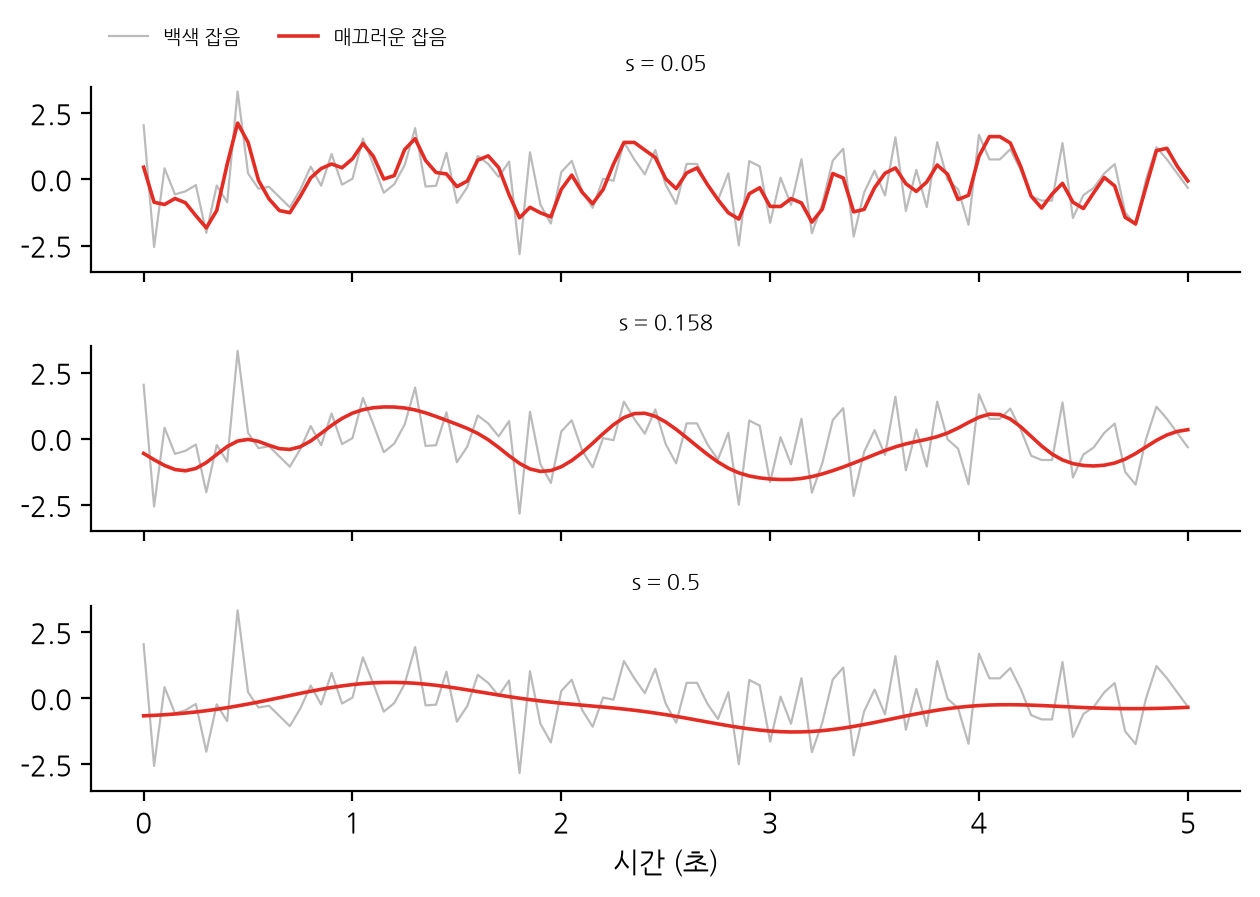

In [5]:
rng = np.random.default_rng(3)
base = rng.standard_normal(N)
fig, ax = plt.subplots(3, 1, sharex=True, figsize=(6.4, 4.6))
for a_, s_ in zip(ax, [0.05, 0.158, 0.5]):
    Pk = toeplitz(np.exp(-t**2 / (2 * s_**2)))
    smooth = base @ Pk @ np.diag(1 / np.sqrt(np.diag(Pk.T @ Pk)))
    a_.plot(t, base, color="#BBBBBB", lw=0.8, label="백색 잡음")
    a_.plot(t, smooth, color="#E32C24", lw=1.3, label="매끄러운 잡음")
    a_.set_title(f"s = {s_}", fontsize=8); a_.set_ylim(-3.5, 3.5)
ax[0].legend(frameon=False, fontsize=7, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.12))
ax[2].set_xlabel("시간 (초)")
fig.tight_layout(); plt.show()

## 4. 자기 상관과 temporalC

가우스 필터 둘을 겹치면 다시 가우스가 되므로, 정규화한 잡음의 자기 상관은 ρ(τ) = exp(−τ²/(4s²)) 다. 필터 자체(분산 s²)가 아니라 분산이 2s² 인 가우스다. 앙상블로 확인한다(가장자리 효과를 피하려고 가운데 시점끼리 비교).

일반화 좌표의 시간 공분산 S 는 이 자기 상관의 원점 도함수로 정해진다: S_ij = (−1)^i ρ^(i+j)(0). 예를 들어 잡음 속도의 분산은 −ρ″(0) = 1/(2s²) 이다. temporalC 가 같은 값을 내는지, 그리고 매끄러운 잡음을 수치 미분한 속도의 분산이 정말 σ²/(2s²) 인지 확인한다(이번에는 2 부처럼 dt = 0.005 를 쓴다).

In [6]:
lags = np.arange(0, 21)
c0 = N // 2
emp = np.array([np.corrcoef(ens[:, 0, c0], ens[:, 0, c0 + L])[0, 1] for L in lags])
theo = np.exp(-(lags * dt)**2 / (4 * s**2))
filt = np.exp(-(lags * dt)**2 / (2 * s**2))
for L in [0, 2, 4, 6, 8]:
    print(f"지연 {L * dt:4.2f}s   앙상블 ρ {emp[L]:+.3f}   이론 exp(−τ²/4s²) {theo[L]:+.3f}   필터 exp(−τ²/2s²) {filt[L]:+.3f}")

def temporalC(p, s2):
    q = np.arange(p + 1); r = np.zeros(1 + 2 * p)
    r[2 * q] = np.cumprod(1 - 2 * q) / (2 * s2)**q
    S = np.empty((0, p + 1))
    for i in range(p + 1):
        S = np.vstack([S, r[q + i]]); r = -r
    return S

print()
s2_sim = 1 / 64
print("temporalC(2, 1/64) =\n", temporalC(2, s2_sim))
print(f"이론: 속도 분산 1/(2s²) = {1 / (2 * s2_sim):.1f},  가속도 분산 3/(2s²)² = {3 / (2 * s2_sim)**2:.1f},  위치와 가속도의 공분산 −1/(2s²) = {-1 / (2 * s2_sim):.1f}")

dt2 = 0.005
t2 = np.arange(0, 6 + dt2 / 2, dt2)
rng = np.random.default_rng(11)
vel_var, acc_var = [], []
for _ in range(300):
    z = makeNoise(1.0, s2_sim, t2, rng)[0]
    mid = z[400:-400]
    vel_var.append(np.var(np.gradient(mid, dt2)))
    acc_var.append(np.var(np.gradient(np.gradient(mid, dt2), dt2)))
print(f"수치 미분: 속도 분산 {np.mean(vel_var):.1f},  가속도 분산 {np.mean(acc_var):.0f}  (σ² = 1)")

지연 0.00s   앙상블 ρ +1.000   이론 exp(−τ²/4s²) +1.000   필터 exp(−τ²/2s²) +1.000
지연 0.10s   앙상블 ρ +0.905   이론 exp(−τ²/4s²) +0.905   필터 exp(−τ²/2s²) +0.818
지연 0.20s   앙상블 ρ +0.673   이론 exp(−τ²/4s²) +0.670   필터 exp(−τ²/2s²) +0.449
지연 0.30s   앙상블 ρ +0.412   이론 exp(−τ²/4s²) +0.406   필터 exp(−τ²/2s²) +0.165
지연 0.40s   앙상블 ρ +0.203   이론 exp(−τ²/4s²) +0.201   필터 exp(−τ²/2s²) +0.041

temporalC(2, 1/64) =
 [[ 1.000e+00  0.000e+00 -3.200e+01]
 [-0.000e+00  3.200e+01 -0.000e+00]
 [-3.200e+01  0.000e+00  3.072e+03]]
이론: 속도 분산 1/(2s²) = 32.0,  가속도 분산 3/(2s²)² = 3072.0,  위치와 가속도의 공분산 −1/(2s²) = -32.0


수치 미분: 속도 분산 31.0,  가속도 분산 2987  (σ² = 1)


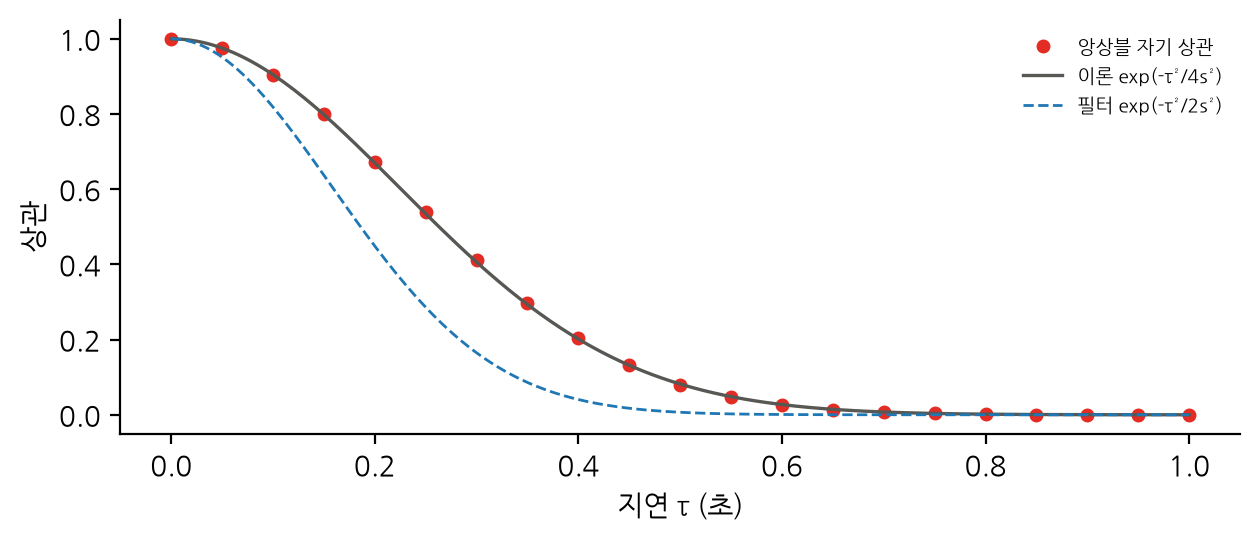

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2.8))
ax.plot(lags * dt, emp, "o", color="#E32C24", ms=4, label="앙상블 자기 상관")
tt = np.linspace(0, lags[-1] * dt, 200)
ax.plot(tt, np.exp(-tt**2 / (4 * s**2)), color="#575753", lw=1.2, label="이론 exp(-τ²/4s²)")
ax.plot(tt, np.exp(-tt**2 / (2 * s**2)), color="#1f77b4", lw=1.0, ls="--", label="필터 exp(-τ²/2s²)")
ax.set_xlabel("지연 τ (초)"); ax.set_ylabel("상관")
ax.legend(frameon=False, fontsize=7)
fig.tight_layout(); plt.show()

## 5. 실패 조건 — 필터가 너무 넓거나 너무 좁을 때

s 를 시간 간격 dt 보다 훨씬 작게 하면 매끄러움이 사라지고, 시뮬레이션 길이 T 에 견줄 만큼 크게 하면 잡음이 한 실현 안에서 거의 상수가 된다. 각 경우에 한 실현의 시간 축 분산(평균 4000 번)과 이웃 시점 상관을 본다.

In [8]:
print("    s       s/dt     한 실현의 시간 축 분산   이웃 시점 상관 ρ(dt)")
rng = np.random.default_rng(5)
for s_ in [0.005, 0.05, 0.158, 0.5, 1.58, 5.0]:
    e = np.array([makeNoise(1.0, s_**2, t, rng)[0] for _ in range(4000)])
    within = e.var(axis=1).mean()
    rho1 = np.corrcoef(e[:, c0], e[:, c0 + 1])[0, 1]
    print(f"{s_:6.3f}   {s_ / dt:7.2f}         {within:6.3f}                {rho1:+.3f}")

    s       s/dt     한 실현의 시간 축 분산   이웃 시점 상관 ρ(dt)


 0.005      0.10          0.990                -0.008


 0.050      1.00          0.967                +0.786


 0.158      3.16          0.890                +0.976


 0.500     10.00          0.681                +0.998


 1.580     31.60          0.227                +1.000


 5.000    100.00          0.007                +1.000


## 결론

- 공분산 Σ 의 백색 잡음은 LL^T = Σ 인 L 을 표준 정규 난수에 곱해 만든다. 촐레스키와 행렬 제곱근 모두 된다.
- 퇴플리츠 행렬과의 곱이 가우스 필터 합성곱이다. 정규화 F 는 각 열의 노름을 1 로 만든다.
- 정규화한 잡음의 앙상블 분산은 입력 Σ 와 같다. 시간 축 표본 분산이 작게 나오는 것은 이웃 시점이 상관되어 한 실현이 평균 주위를 충분히 돌아다니지 못하기 때문이다.
- 자기 상관은 필터보다 두 배 넓은 가우스 exp(−τ²/4s²) 이고, 그 원점 도함수가 temporalC 의 시간 공분산이다. 매끄러운 잡음의 속도 분산은 σ²/(2s²) 다.
- s 가 dt 보다 훨씬 작으면 백색 잡음과 같고, T 에 견줄 만큼 크면 한 실현 안에서 거의 상수가 된다.